# Experiment 03: Study of Frequency Allocation and Channel Assignment in Cellular Networks

**Course:** Mobile and Cellular Communication Laboratory  
**Course Code:** ICT-4204  
**Department:** Department of Information and Communication Technology, Islamic University, Kushtia, Bangladesh  
**Implementation:** Python / Jupyter Notebook

---
**Course-source basis:** Chapter 5 (Frequency Management and Channel Assignment) and the course Master Study Notes.

> This notebook is an educational laboratory implementation. It keeps the mathematical model simple enough to explain in a practical examination while preserving the core cellular-communication ideas.

## Aim

To study frequency allocation and fixed channel assignment in cellular networks and visualize frequency distribution, hexagonal frequency reuse, and uplink/downlink channel mapping.

## Objectives

- Understand frequency management and channel assignment.
- Distinguish fixed and dynamic/non-fixed channel assignment.
- Allocate channels among cells using a simple reuse-friendly pattern.
- Simulate call demand, served calls, and blocked calls.
- Explain why fixed allocation can leave channels idle in one cell while another cell is congested.

## Theory

A cellular network divides a geographical service area into smaller regions called **cells**, each served by a base station. Because the available radio-frequency spectrum is limited, efficient frequency allocation and channel assignment are essential.

**Frequency Allocation:** The process of dividing available radio spectrum into frequency channels for communication.

**Channel Assignment:** The process of allocating specific frequency channels to cellular base stations or mobile users.

### Types of Channel Assignment

**1. Fixed Channel Assignment (FCA)**

In FCA, each cell has a predetermined channel set:

$$
\mathcal{C}_k=\{\text{channels permanently assigned to cell }k\}
$$

If every channel in $\mathcal{C}_k$ is busy, a new call in that cell is blocked even if another cell has idle channels.

**2. Dynamic / Non-Fixed Channel Assignment**

In dynamic or non-fixed assignment, channels are drawn from a common or adaptable pool according to current demand and interference conditions. This improves flexibility but requires more real-time control.

The MATLAB program demonstrates a simplified FCA scheme.

## Mathematical Formulation

### 1. Total Number of Channels

The number of available paired channels is

$$
M = \left\lfloor \frac{1000B}{b_w} \right\rfloor
$$

where:

- $M$ = total number of paired channels
- $B$ = available bandwidth per direction (MHz)
- $b_w$ = channel spacing (kHz)

Given:

$$
B = 25\text{ MHz}, \qquad b_w = 200\text{ kHz}
$$

Therefore,

$$
M = \frac{25\times1000}{200}=125
$$

Hence, the system contains **125 paired channels**.

### 2. Uplink and Downlink Frequencies

For channel number $k$, the uplink frequency is

$$
f_{UL}(k)=f_0+(k-1)\frac{b_w}{1000}
$$

The corresponding downlink frequency is

$$
f_{DL}(k)=f_{UL}(k)+\Delta f
$$

where:

- $f_0=890$ MHz is the first uplink frequency
- $\Delta f=45$ MHz is the duplex separation
- $k=1,2,\ldots,125$

Thus, the illustrated uplink and downlink frequency ranges are:

- Uplink: **890.0–914.8 MHz**
- Downlink: **935.0–959.8 MHz**

### 3. Cluster Size and Frequency Reuse

Frequency reuse allows the same channel groups to be used in sufficiently separated cells.

The cluster size is

$$
N=i^2+ij+j^2
$$

For $i=2$ and $j=1$,

$$
N=2^2+(2)(1)+1^2=7
$$

The frequency reuse factor is

$$
\frac{1}{N}=\frac{1}{7}
$$

The co-channel reuse distance is

$$
D=R\sqrt{3N}
$$

The reuse ratio is

$$
q=\frac{D}{R}=\sqrt{3N}
$$

For $N=7$,

$$
q=\sqrt{21}\approx4.583
$$

A larger reuse distance generally reduces co-channel interference but also reduces frequency-reuse efficiency.

### 4. Channel Distribution

The number of channels initially assigned to each frequency group is

$$
c=\left\lfloor\frac{M}{N}\right\rfloor
$$

With $M=125$ and $N=7$,

$$
125=7(17)+6
$$

Therefore:

- Groups F1–F6 receive 18 channels each.
- Group F7 receives 17 channels.

## Graphical Analysis

The MATLAB program produces four visualizations:

1. **Frequency Allocation:** Shows the allocation of uplink frequencies to seven cell groups.
2. **Channels per Cell:** Shows the number of channels assigned to each group.
3. **Hexagonal Frequency Reuse:** Illustrates how frequency groups F1–F7 repeat across a cellular network.
4. **Uplink and Downlink Mapping:** Shows paired frequencies separated by 45 MHz.

## Result and Discussion

The experiment successfully allocates 125 paired channels among seven frequency groups using fixed channel assignment.

The hexagonal layout demonstrates frequency reuse, while the uplink/downlink mapping illustrates duplex-frequency separation.

This is an illustrative frequency-planning model rather than a complete interference-aware cellular network simulation.

## Conclusion

Frequency allocation and fixed channel assignment were studied using MATLAB. The experiment demonstrates how limited radio spectrum can be divided, assigned, and reused to support cellular communication efficiently.


EXPERIMENT 03 - ILLUSTRATIVE FREQUENCY PLAN
Cluster size N: 7 (i=2, j=1)
Paired duplex channels: 125  (guard bands ignored)
Uplink range: 890.0 to 914.8 MHz
Downlink range: 935.0 to 959.8 MHz
Co-channel center distance: 4.583 km
Group 1: 18 channels
Group 2: 18 channels
Group 3: 18 channels
Group 4: 18 channels
Group 5: 18 channels
Group 6: 18 channels
Group 7: 17 channels


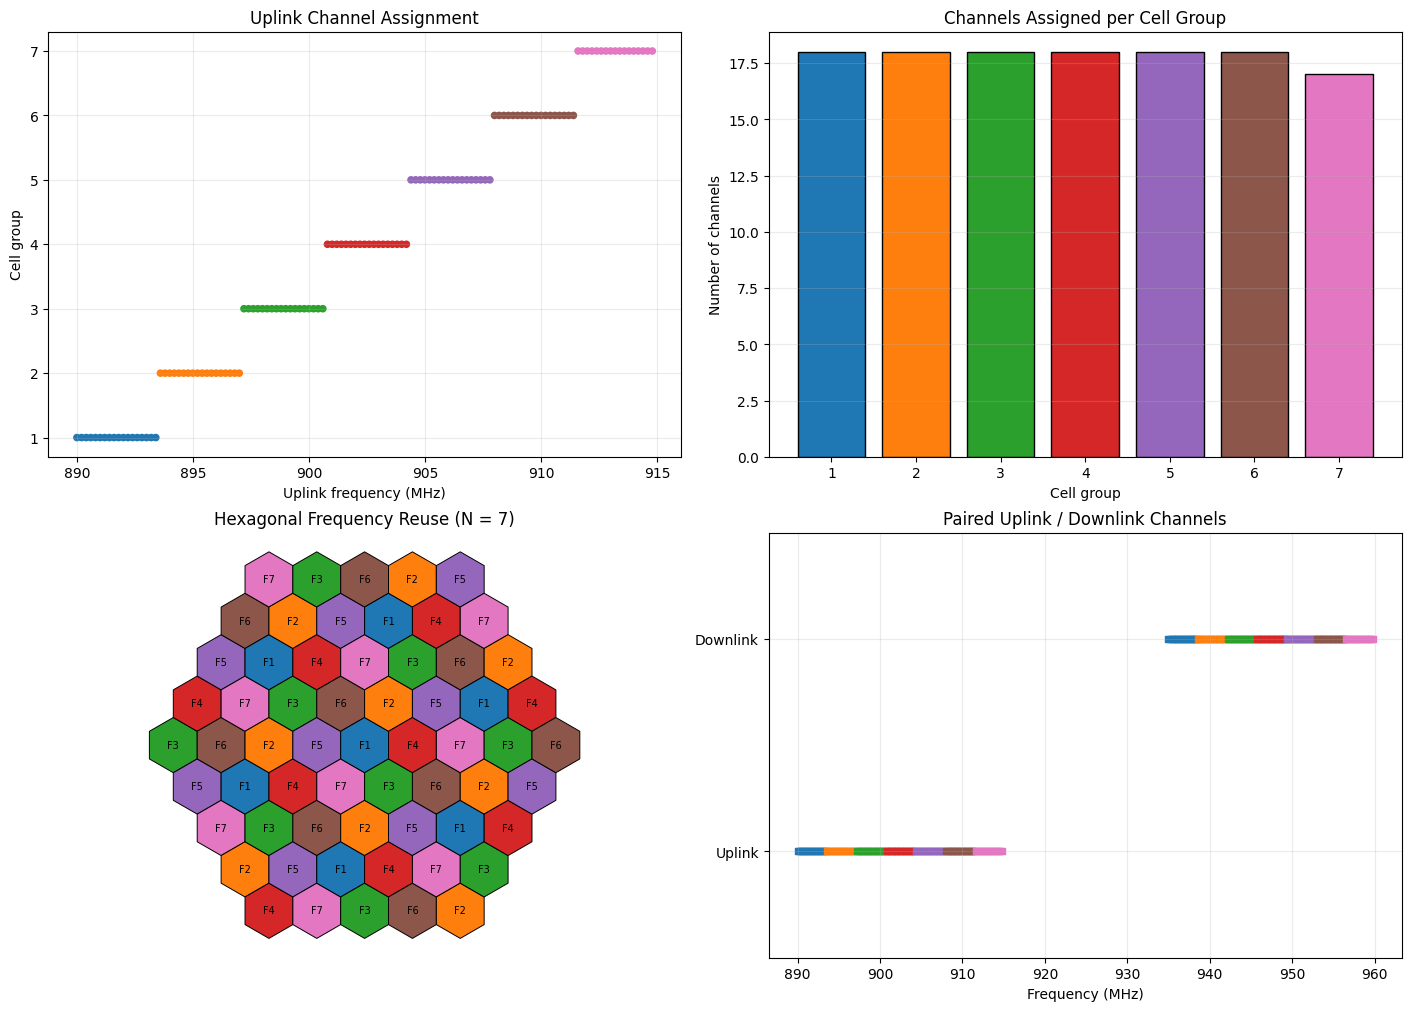

(7, 125, array([18, 18, 18, 18, 18, 18, 17]))

In [2]:
"""Experiment 03: Frequency allocation and channel assignment.

Python translation and simplification of the supplied classmate MATLAB E3 plot.
This is an ADDITIONAL 125-channel illustrative planning example; it does not
replace the existing EXP03 notebook's 70-channel traffic-demand example.

Uses only NumPy and Matplotlib. Run with:
    python EXP03_MATLAB_Style_Visualizations.py
"""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

# Change these values to try another scenario.
BANDWIDTH_MHZ = 25.0       # illustrative spectrum in EACH direction
CHANNEL_SPACING_KHZ = 200.0
UPLINK_START_MHZ = 890.0
DUPLEX_SPACING_MHZ = 45.0
I, J = 2, 1                # reuse shift: N = I^2 + I*J + J^2 = 7
CELL_RADIUS_KM = 1.0
ASSIGNMENT = "sequential"  # or "interleaved"
GRID_RADIUS = 4            # rings of hexagonal cells shown in the plot


def allocate_channels(total_channels, group_count, method):
    """Assign channel numbers to group IDs 1..N using FCA."""
    if method == "interleaved":
        return np.arange(total_channels) % group_count + 1
    if method == "sequential":
        equal_count, remainder = divmod(total_channels, group_count)
        counts = [equal_count + (group < remainder)
                  for group in range(group_count)]
        return np.repeat(np.arange(1, group_count + 1), counts)
    raise ValueError("ASSIGNMENT must be 'sequential' or 'interleaved'")


def axial_to_xy(q, r, radius):
    """Hex-grid coordinates to kilometers for pointy-top hexagons."""
    return (np.sqrt(3) * radius * (q + r / 2), 1.5 * radius * r)


def hex_vertices(cx, cy, radius):
    """Vertices in consistent order so neighboring hexagons touch."""
    angles = np.deg2rad(np.arange(30, 390, 60))
    return np.column_stack((cx + radius * np.cos(angles),
                            cy + radius * np.sin(angles)))


def make_reuse_grid(i, j, ring_count):
    """Return (q, r, group) for a valid N=i^2+ij+j^2 reuse pattern.

    Two modular coordinates are used so the pattern also works for
    valid cases such as (i,j)=(2,0), where a one-residue trick fails.
    """
    n = i * i + i * j + j * j
    coords = [(q, r)
              for q in range(-ring_count, ring_count + 1)
              for r in range(-ring_count, ring_count + 1)
              if max(abs(q), abs(r), abs(q + r)) <= ring_count]

    def residue(q, r):
        return (((i + j) * q + j * r) % n,
                (-j * q + i * r) % n)

    residue_keys = sorted({residue(q, r) for q, r in coords})
    if len(residue_keys) != n:
        raise ValueError("Use more grid rings to display all frequency groups")
    group_by_key = {key: k + 1 for k, key in enumerate(residue_keys)}
    return [(q, r, group_by_key[residue(q, r)]) for q, r in coords]


def plot_frequency_planning(ul, dl, cell_group, counts, colors, reuse_grid, radius, n):
    """Recreate the four informative views from the MATLAB experiment."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
    ax1, ax2, ax3, ax4 = axes.flat

    # 1. Each point is one assigned uplink channel.
    ax1.scatter(ul, cell_group, s=20, c=colors[cell_group - 1])
    ax1.set(xlabel="Uplink frequency (MHz)", ylabel="Cell group",
            title="Uplink Channel Assignment")
    ax1.set_yticks(range(1, n + 1))
    ax1.grid(alpha=0.25)

    # 2. Channel capacity by group (not traffic demand).
    ax2.bar(range(1, n + 1), counts, color=colors, edgecolor="black")
    ax2.set(xlabel="Cell group", ylabel="Number of channels",
            title="Channels Assigned per Cell Group")
    ax2.set_xticks(range(1, n + 1))
    ax2.grid(axis="y", alpha=0.25)

    # 3. Hexagonal pattern: 7 frequencies are reused in distant cells.
    for q, r, group in reuse_grid:
        x, y = axial_to_xy(q, r, radius)
        ax3.add_patch(Polygon(hex_vertices(x, y, radius), closed=True,
                              facecolor=colors[group - 1],
                              edgecolor="black", linewidth=0.7))
        ax3.text(x, y, f"F{group}", ha="center", va="center", fontsize=7)
    ax3.set_aspect("equal", adjustable="box")
    ax3.relim()
    ax3.autoscale_view()
    ax3.axis("off")
    ax3.set_title(f"Hexagonal Frequency Reuse (N = {n})")

    # 4. Each uplink carrier has a downlink partner offset by DUPLEX_SPACING.
    ax4.scatter(ul, np.ones_like(ul), c=colors[cell_group - 1], s=19, marker="s")
    ax4.scatter(dl, np.ones_like(dl) * 2, c=colors[cell_group - 1], s=19, marker="s")
    ax4.set(xlabel="Frequency (MHz)", title="Paired Uplink / Downlink Channels")
    ax4.set_yticks([1, 2], ["Uplink", "Downlink"])
    ax4.set_ylim(0.5, 2.5)
    ax4.grid(alpha=0.25)
    return fig


def main(save_dir=None):
    n = I**2 + I*J + J**2
    if n < 1 or CHANNEL_SPACING_KHZ <= 0 or BANDWIDTH_MHZ <= 0:
        raise ValueError("Enter positive spectrum, channel spacing, and valid reuse indices")
    if CELL_RADIUS_KM <= 0:
        raise ValueError("Cell radius must be positive")

    total = int(np.floor(BANDWIDTH_MHZ * 1000 / CHANNEL_SPACING_KHZ))
    channel_ids = np.arange(1, total + 1)
    cell_group = allocate_channels(total, n, ASSIGNMENT)
    counts = np.bincount(cell_group, minlength=n + 1)[1:]
    uplink_mhz = UPLINK_START_MHZ + (channel_ids - 1) * CHANNEL_SPACING_KHZ / 1000
    downlink_mhz = uplink_mhz + DUPLEX_SPACING_MHZ
    reuse_grid = make_reuse_grid(I, J, GRID_RADIUS)

    # Exact physical check of the reuse distance for shift (I,J).
    x, y = axial_to_xy(I, J, CELL_RADIUS_KM)
    expected_d = CELL_RADIUS_KM * np.sqrt(3 * n)
    assert np.isclose(np.hypot(x, y), expected_d)
    assert len(reuse_grid) > 0 and len(np.unique([v[2] for v in reuse_grid])) == n
    assert counts.sum() == total

    print("EXPERIMENT 03 - ILLUSTRATIVE FREQUENCY PLAN")
    print(f"Cluster size N: {n} (i={I}, j={J})")
    print(f"Paired duplex channels: {total}  (guard bands ignored)")
    print(f"Uplink range: {uplink_mhz[0]:.1f} to {uplink_mhz[-1]:.1f} MHz")
    print(f"Downlink range: {downlink_mhz[0]:.1f} to {downlink_mhz[-1]:.1f} MHz")
    print(f"Co-channel center distance: {expected_d:.3f} km")
    for group, count in enumerate(counts, 1):
        print(f"Group {group}: {int(count)} channels")

    palette = np.array(plt.get_cmap("tab10").colors[:n])
    fig = plot_frequency_planning(uplink_mhz, downlink_mhz,
                                  cell_group, counts, palette,
                                  reuse_grid, CELL_RADIUS_KM, n)
    if save_dir is not None:
        from pathlib import Path
        out = Path(save_dir)
        out.mkdir(parents=True, exist_ok=True)
        fig.savefig(out / "EXP03_Frequency_Planning.png", dpi=170, bbox_inches="tight")
    else:
        plt.show()
    return n, total, counts



main()

**Extended observation.** The first six cell groups receive 18 channels each, and the last group receives 17, because $125 = 6\times18+17$. The hexagonal map repeats the same seven frequency groups at spatially separated cells. Uplink and downlink carriers form paired channels separated by 45 MHz. These plots complement (rather than replace) the earlier blocked-call FCA demonstration.

## Fixed vs Dynamic Assignment — Practical Comparison

| Feature | Fixed Channel Assignment | Dynamic / Non-Fixed Assignment |
|---|---|---|
| Channel ownership | Predetermined per cell | Selected according to current need |
| Complexity | Low | Higher |
| Signalling/control | Lower | Higher |
| Response to uneven traffic | Weak | Better |
| Call blocking under local congestion | Can be high | Can be reduced if reusable channels are available |
| Interference control | Planned in advance | Must be checked during assignment |

## Result and Discussion

The notebook allocates a fixed channel set to each cell and demonstrates local blocking under uneven traffic. This is the main weakness of FCA: resources cannot automatically move to a congested cell.

## Conclusion

Frequency allocation and fixed channel assignment were implemented successfully. The simulation clearly shows the difference between **system-wide unused capacity** and **local channel availability**.

## Viva Questions and Short Answers

1. **What is frequency management?**  
   Planning set-up/voice channels, channel numbering, and grouping according to the system plan.

2. **What is channel assignment?**  
   Allocation of radio channels to cells and mobile users.

3. **What is the main idea of FCA?**  
   Each cell receives a predetermined channel set.

4. **Why can FCA block a call even when the network has idle channels?**  
   Because idle channels in another cell are not automatically available to the congested cell.

5. **What is the main advantage of dynamic assignment?**  
   It adapts channel use to current traffic and can improve spectrum utilization.